# Project: <your topic here>
> Data Mining · SGH Warsaw School of Economics (223121-0090)

| | |
|---|---|
| **Team** | *Jagger Onstott · Connor Richardson · Youssef Rbahi* |
| **Dataset** | *Hotel Booking Demand + https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand* |

**How to use this template.** Each numbered section matches one criterion of
the project rubric; the percentage in its heading is its weight. Replace every
*TODO* with your own work and keep the section order. If a step does not apply
to your data, say why in one sentence instead of deleting it.

**Rules**
1. *Kernel → Restart & Run All* must run without errors before you upload.
2. The notebook you upload before Block 7 is final.
3. AI assistants are not recommended, but allowed. You answer for every line:
   submissions are read for signs of unchecked generation, and work you cannot
   explain counts as work you did not do.

In [1]:
# Setup: keep this cell first
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
pd.set_option("display.max_columns", 50)

SEED = 42  # use this seed everywhere
np.random.seed(SEED)

## 1. Business framing and problem definition (10%)

Describe the business problem and your research question (hypothesis), with a
short literature background. Cover:

- **Decision:** who acts on the model's output, and what they do differently.
- **Unit of analysis:** what one row is.
- **Target:** how it is defined, and when it becomes known relative to the moment of prediction.
- **Cost of errors:** what a false positive and a false negative cost (rough ratios are enough; Section 5 uses them).
- **Success criterion:** what result would justify using the model.

**Business problem.** Hotels lose revenue when a guest cancels and the room stays empty. Many hotels overbook to compensate, but overbooking too far means turning away guests who show up, which costs money and reputation. Deposits and reconfirmation requests are other tools, and all of them work better if the hotel knows which bookings are likely to be cancelled.

**Research question and hypothesis.** Can booking characteristics known around the time of reservation predict cancellation well enough to support these decisions? We expect lead time, deposit type, market segment and previous cancellations to be the strongest predictors, and we expect a gradient boosting model to outperform logistic regression because cancellation behavior likely involves interactions and non-linear effects.

**Literature background.** The data come from Antonio, Almeida and Nunes (2019), "Hotel booking demand datasets", *Data in Brief*, which describes real bookings from a resort hotel and a city hotel in Portugal. The same authors studied cancellation prediction in earlier work (2017, *Tourism & Management Studies*) and report that booking-level features can predict cancellations reasonably well. Cancellation forecasting is also a standard input to revenue management and overbooking policy.

**Decision.** A hotel revenue manager decides, at booking time, which reservations to treat as high cancellation risk. Flagged bookings get a deposit or reconfirmation request, and their predicted risk feeds into the overbooking level for that date.

**Unit of analysis.** One row is one hotel booking (resort or city hotel, arrivals July 2015 to August 2017).

**Target.** `is_canceled` (1 = cancelled, 0 = guest stayed). The outcome is only known on or before the arrival date, so every feature must be available at or shortly after booking. Columns that reveal the outcome, such as `reservation_status` and `reservation_status_date`, are excluded. Columns that can change after booking, such as `assigned_room_type`, `booking_changes` and `days_in_waiting_list`, are checked in the leakage audit in Section 3.

**Cost of errors.** A false negative is a cancellation we missed. The room goes empty, which we assume costs about one night of revenue. A false positive is a guest flagged as risky who would have come. Asking for a deposit may lose the booking or hurt goodwill, which we assume costs about one third of a night. That gives a cost ratio of roughly 3:1. With these costs, flagging a booking is worthwhile when its predicted cancellation probability is above 1 / (1 + 3) = 0.25, so Section 5 will use a threshold near 0.25 instead of 0.5. We will also test how sensitive the result is to other ratios.

**Success criterion.** The flexible model should beat logistic regression on PR-AUC by more than the cross-validation standard deviation and lower the expected cost per booking at the chosen threshold. Its predicted probabilities should also be reasonably well calibrated, since the cost-based threshold depends on them.

## 2. Data understanding (EDA)

Source and description of the data, descriptive statistics, the distribution
of the target, and missing values: how many, where, and why. This section
counts towards the criterion of Section 3.

In [2]:
# TODO: load the data

# Load the raw booking data (the CSV sits in the same folder as the notebook)
df = pd.read_csv("hotel_bookings.csv")

# Size check. These two numbers go into the topic description
print("Rows, columns:", df.shape)
print()

# Column names, data types and non-null counts
df.info()
print()

Rows, columns: (119390, 32)

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12

In [3]:
# TODO: descriptive statistics, distributions, relationships with the target, missing values

# Target balance, missingness, duplicates

# Class balance of the target (1 = cancelled)
print(df["is_canceled"].value_counts())
print()
print(df["is_canceled"].value_counts(normalize=True).round(3))
print()

# Missing values, only for columns that have any
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(pd.DataFrame({"missing": missing, "share": (missing / len(df)).round(4)}))
print()

# Exact duplicate rows (this dataset has a lot, which matters for the train/test split)
print("Duplicate rows:", df.duplicated().sum())

is_canceled
0    75166
1    44224
Name: count, dtype: int64

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64

          missing   share
company    112593  0.9431
agent       16340  0.1369
country       488  0.0041
children        4  0.0000

Duplicate rows: 31994


In [4]:
# Evidence for the leakage audit and the missingness mechanism

# reservation_status is the outcome in another form, so it cannot be a feature
print(pd.crosstab(df["reservation_status"], df["is_canceled"]))
print()

# Is "missing agent" related to cancellation? Helps decide MCAR vs structural missingness
print(df.groupby(df["agent"].isna())["is_canceled"].mean().round(3))
print()
print(df.groupby(df["company"].isna())["is_canceled"].mean().round(3))
print()

# Cancellation rate by deposit type (look closely at "Non Refund", it looks odd)
print(df.groupby("deposit_type")["is_canceled"].agg(["mean", "count"]).round(3))

is_canceled             0      1
reservation_status              
Canceled                0  43017
Check-Out           75166      0
No-Show                 0   1207

agent
False    0.390
True     0.247
Name: is_canceled, dtype: float64

company
False    0.175
True     0.382
Name: is_canceled, dtype: float64

               mean   count
deposit_type               
No Deposit    0.284  104641
Non Refund    0.994   14587
Refundable    0.222     162


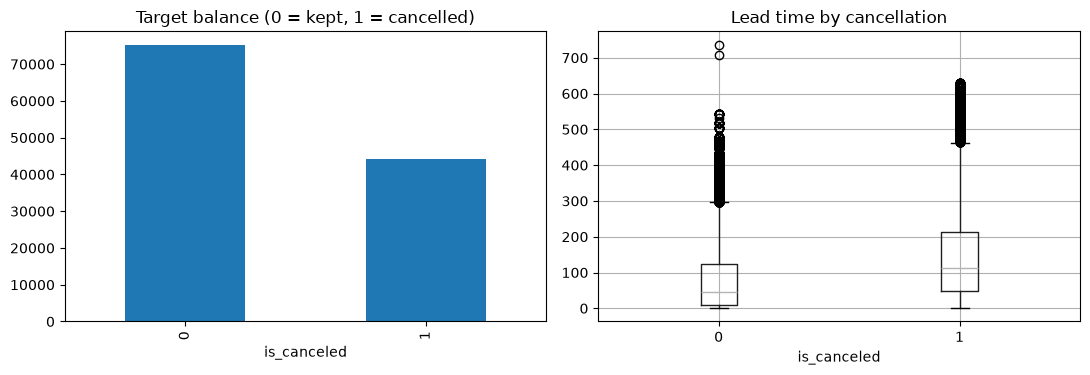

In [5]:
# First plot

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

# Target balance
df["is_canceled"].value_counts().sort_index().plot.bar(ax=axes[0])
axes[0].set_title("Target balance (0 = kept, 1 = cancelled)")

# Lead time by outcome, a likely strong predictor
df.boxplot(column="lead_time", by="is_canceled", ax=axes[1])
axes[1].set_title("Lead time by cancellation")
plt.suptitle("")
plt.tight_layout()
plt.show()

**Data-quality risks:** your top three, and how you will handle each.

1. Duplicate rows. 31,994 rows (26.8%) are exact duplicates. If copies land in both train and test, test scores look better than they are. We will drop duplicates before splitting and report the effect on the cancellation rate.

2. Structural missingness in agent and company. Missing agent and company values are linked to cancellation (24.7% vs 39.0% for agent, 38.2% vs 17.5% for company), so they are not random. They most likely mean “no agent” or “no company”. We will add missing-indicator flags and fill with a constant instead of the mean. country and children have almost no missing values, so a simple fill is fine.

3. Leakage and suspicious columns. reservation_status perfectly reproduces the target and will be dropped along with reservation_status_date. The Non Refund deposit type shows a 99.4% cancellation rate, which looks like a data artifact. We will keep it in the audit and check how much the model depends on it.

## 3. Data preparation and missing values (15%)

Split the data before any transformation, and fit every transformation
(imputation, scaling, encoding) on the training set only, inside a `Pipeline`
where possible.

In [6]:
# Leakage evidence for the borderline columns

# Columns that may only be filled in after the booking: compare them by outcome
cols = ["required_car_parking_spaces", "booking_changes",
        "total_of_special_requests", "days_in_waiting_list"]
print(df.groupby("is_canceled")[cols].mean().round(3))

# Share of bookings where the assigned room differs from the reserved room
same_room = df["assigned_room_type"] == df["reserved_room_type"]
print(pd.crosstab(same_room, df["is_canceled"], normalize="columns").round(3))

# Parking: does any cancelled booking have a parking space at all?
print(df.loc[df["is_canceled"] == 1, "required_car_parking_spaces"].value_counts())

             required_car_parking_spaces  booking_changes  \
is_canceled                                                 
0                                  0.099            0.293   
1                                  0.000            0.098   

             total_of_special_requests  days_in_waiting_list  
is_canceled                                                   
0                                0.714                 1.590  
1                                0.329                 3.564  
is_canceled      0      1
row_0                    
False        0.188  0.018
True         0.812  0.982
required_car_parking_spaces
0    44224
Name: count, dtype: int64


In [7]:
# Cleaning, dropping columns, and the split
from sklearn.model_selection import train_test_split

data = df.copy()

# 1. Drop exact duplicates so identical bookings can't end up in both train and test
n_before = len(data)
data = data.drop_duplicates()
print(f"Dropped {n_before - len(data)} duplicate rows")

# 2. Drop impossible rows: no guests at all, or a negative price
no_guests = (data["adults"] + data["children"].fillna(0) + data["babies"]) == 0
bad_adr = data["adr"] < 0
print("Zero-guest rows:", no_guests.sum(), "| negative adr rows:", bad_adr.sum())
data = data[~(no_guests | bad_adr)]

# 3. Missing flags for agent and company. This only looks at each row itself,
#    so it is safe to do before the split
data["agent_missing"] = data["agent"].isna().astype(int)
data["company_missing"] = data["company"].isna().astype(int)
data["agent"] = data["agent"].fillna(0).astype(int).astype(str)  # agent is an ID, so treat as a category

# 4. Drop columns that leak the outcome or aren't known at prediction time (see audit table)
drop_cols = [
    "reservation_status", "reservation_status_date",   # the outcome itself
    "assigned_room_type", "booking_changes",            # set after booking
    "required_car_parking_spaces",                      # filled in at check-in
    "company",                                          # 94% missing, only the flag is kept
    "arrival_date_year",                                # only 2015-2017, can't generalise
]
X = data.drop(columns=drop_cols + ["is_canceled"])
y = data["is_canceled"]
print("Cancellation rate after cleaning:", y.mean().round(3))

# 5. Stratified split. The test set stays untouched until Section 5
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Cancel rate train / test:", y_train.mean().round(3), "/", y_test.mean().round(3))

Dropped 31994 duplicate rows
Zero-guest rows: 166 | negative adr rows: 1
Cancellation rate after cleaning: 0.275
Train: (69783, 26) | Test: (17446, 26)
Cancel rate train / test: 0.275 / 0.275


In [8]:
# Preprocessing pipeline
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Split columns by type
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Numbers: median fill with a missing-indicator flag, then scale (needed for logistic regression)
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median", add_indicator=True)),
    ("scale", StandardScaler()),
])

# Categories: missing values become their own "missing" level, then one-hot encode.
# Rare levels (under 1% of rows, e.g. most agent IDs and countries) are grouped together
categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="constant", fill_value="missing")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=0.01)),
])

prep = ColumnTransformer(
    [("num", numeric_pipe, num_cols), ("cat", categorical_pipe, cat_cols)],
    sparse_threshold=0,  # return a normal array so we can check it easily
)

# Sanity check only: fit on TRAIN, then transform both sets with the fitted rules
Xt_train = prep.fit_transform(X_train)
Xt_test = prep.transform(X_test)
print("Transformed shapes:", Xt_train.shape, Xt_test.shape)
print("Any NaN left:", np.isnan(Xt_train).any(), np.isnan(Xt_test).any())

Transformed shapes: (69783, 88) (17446, 88)
Any NaN left: False False


**Leakage audit:** for every feature, is its value known at the moment of
prediction? List the features you dropped, and why.

| Feature | Known at prediction time? | Kept / dropped |
|---|---|---|
| hotel, lead_time, meal, country | Yes, set at booking | Kept |
| arrival_date_month, arrival_date_week_number, arrival_date_day_of_month | Yes, the arrival date is stated at booking | Kept |
| arrival_date_year | Yes, but data covers only 2015 to 2017 | Dropped, cannot generalise to future years |
| stays_in_weekend_nights, stays_in_week_nights | Yes, planned stay | Kept |
| adults, children, babies | Yes, though they can be edited later | Kept |
| market_segment, distribution_channel, customer_type | Yes | Kept |
| is_repeated_guest, previous_cancellations, previous_bookings_not_canceled | Yes, based on earlier bookings | Kept |
| reserved_room_type | Yes | Kept |
| deposit_type | Yes, set at booking | Kept, but Non Refund has a 99.4% cancellation rate, which looks like a data artifact |
| agent | Yes | Kept as a category plus a missing flag |
| company | Yes | Dropped, 94% missing, only the missing flag is kept |
| days_in_waiting_list | Mostly, known once the booking is confirmed | Kept, borderline (3.56 days for cancelled vs 1.59 for kept) |
| adr | Mostly, price at booking, may include later extras | Kept, borderline |
| total_of_special_requests | Partly, requests can be added after booking | Kept, borderline (0.33 for cancelled vs 0.71 for kept) |
| assigned_room_type | No, assigned at or near check-in (18.8% of kept bookings got a different room vs 1.8% of cancelled) | Dropped |
| booking_changes | No, counts changes made after booking (0.29 for kept vs 0.10 for cancelled) | Dropped |
| required_car_parking_spaces | No, filled in at check-in (0 for all 44,224 cancelled bookings) | Dropped |
| reservation_status | No, it is the outcome | Dropped |
| reservation_status_date | No, it is the date of the outcome | Dropped |

## 4. Modelling: at least two model families (15%)

Model I is a simple, transparent baseline, such as logistic regression. Model II
is a more flexible family that has to beat it. Justify both choices and your
tuning.

In [9]:
# imports and shared setup
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV, RandomizedSearchCV

# Same 5 stratified folds for both models, so the comparison is fair
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# PR-AUC (average precision) is the main metric because cancellations are the minority class.
# ROC-AUC is tracked as a second view.
scoring = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}

# A model that guesses at random gets a PR-AUC equal to the cancellation rate
print("PR-AUC of a random model:", y_train.mean().round(3))

PR-AUC of a random model: 0.275


In [10]:
# Model I, logistic regression

# Preprocessing + model in one pipeline (clone gives a fresh, unfitted copy of prep)
logreg_pipe = Pipeline([
    ("prep", clone(prep)),
    ("model", LogisticRegression(max_iter=2000)),
])

# Only one setting to tune: C, the regularisation strength (smaller = simpler model)
logreg_grid = {"model__C": [0.01, 0.1, 1, 10]}

logreg_search = GridSearchCV(
    logreg_pipe, logreg_grid, scoring=scoring, refit="pr_auc",
    cv=cv, n_jobs=-1,
)
logreg_search.fit(X_train, y_train)  # training data only
print("Best C:", logreg_search.best_params_)

Best C: {'model__C': 10}


In [11]:
# Model II, gradient boosting

# Same preprocessing, but the model is a gradient boosted tree ensemble
gb_pipe = Pipeline([
    ("prep", clone(prep)),
    ("model", HistGradientBoostingClassifier(
        early_stopping=True, max_iter=500, random_state=SEED)),
])

# Settings to search. Random search tries 15 combinations instead of all of them
gb_params = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [15, 31, 63],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [0.0, 1.0, 10.0],
}

gb_search = RandomizedSearchCV(
    gb_pipe, gb_params, n_iter=15, scoring=scoring, refit="pr_auc",
    cv=cv, n_jobs=-1, random_state=SEED,
)
gb_search.fit(X_train, y_train)  # training data only
print("Best settings:", gb_search.best_params_)

Best settings: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 63, 'model__learning_rate': 0.05, 'model__l2_regularization': 10.0}


In [12]:
# compare both models on cross-validation

# Pull mean and standard deviation of each metric for the best setting of each model
def cv_row(search, name):
    i = search.best_index_
    r = search.cv_results_
    return {
        "model": name,
        "PR-AUC mean": r["mean_test_pr_auc"][i],
        "PR-AUC sd": r["std_test_pr_auc"][i],
        "ROC-AUC mean": r["mean_test_roc_auc"][i],
        "ROC-AUC sd": r["std_test_roc_auc"][i],
    }

cv_table = pd.DataFrame([
    cv_row(logreg_search, "Logistic regression"),
    cv_row(gb_search, "Gradient boosting"),
]).round(3)
print(cv_table)

                 model  PR-AUC mean  PR-AUC sd  ROC-AUC mean  ROC-AUC sd
0  Logistic regression        0.635      0.005         0.824       0.002
1    Gradient boosting        0.763      0.004         0.891       0.002


In [13]:
# Optional: widen the grids because the best values were at the upper edge (wider-grid rerun (logreg_search2 and gb_search2))
logreg_search2 = GridSearchCV(
    logreg_pipe, {"model__C": [1, 10, 100, 1000]},
    scoring=scoring, refit="pr_auc", cv=cv, n_jobs=-1,
).fit(X_train, y_train)

gb_params2 = {
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_leaf_nodes": [31, 63, 127, 255],
    "model__min_samples_leaf": [20, 50, 100],
    "model__l2_regularization": [1.0, 10.0, 30.0, 100.0],
}
gb_search2 = RandomizedSearchCV(
    gb_pipe, gb_params2, n_iter=15, scoring=scoring, refit="pr_auc",
    cv=cv, n_jobs=-1, random_state=SEED,
).fit(X_train, y_train)

print(logreg_search2.best_params_, gb_search2.best_params_)
print(pd.DataFrame([cv_row(logreg_search2, "Logistic regression"),
                    cv_row(gb_search2, "Gradient boosting")]).round(3))

{'model__C': 1000} {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 127, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0}
                 model  PR-AUC mean  PR-AUC sd  ROC-AUC mean  ROC-AUC sd
0  Logistic regression        0.635      0.005         0.824       0.002
1    Gradient boosting        0.766      0.004         0.892       0.003


In [14]:
# Final models for Section 5: C=10 for logistic regression (same score as C=1000, more regularised),
# and the wider-search result for gradient boosting
gb_search = gb_search2

cv_table = pd.DataFrame([
    cv_row(logreg_search, "Logistic regression"),
    cv_row(gb_search, "Gradient boosting"),
]).round(3)
print(cv_table)

                 model  PR-AUC mean  PR-AUC sd  ROC-AUC mean  ROC-AUC sd
0  Logistic regression        0.635      0.005         0.824       0.002
1    Gradient boosting        0.766      0.004         0.892       0.003


**Model I: logistic regression.** It is simple, fast and easy to explain to a hotel manager, since each coefficient shows how a feature moves the odds of cancellation. It also tends to give reasonably calibrated probabilities, which matters because our cost-based threshold in Section 5 depends on them. We tune only the regularisation strength C.

**Model II: gradient boosting.** Cancellation behaviour probably involves interactions (for example, lead time matters differently by deposit type or market segment) and non-linear effects that logistic regression cannot capture without manual feature work. Gradient boosted trees handle these automatically and work well on mixed tabular data. We use scikit-learn's histogram-based version because it is fast on this many rows.

**Tuning.** Both models are tuned with 5-fold stratified cross-validation on the training set only, using PR-AUC as the selection metric. We chose PR-AUC because cancellations are the minority class (about 27.5% after cleaning), and it focuses on how well the model ranks risky bookings. We did not use class weights or resampling, because they distort predicted probabilities and our threshold in Section 5 needs honest probabilities. Gradient boosting uses a random search of 15 combinations to keep run time reasonable. The test set is not used in any of this.

**Results.** In 5-fold cross-validation on the training set, gradient boosting reached a PR-AUC of 0.766 ± 0.004 and a ROC-AUC of 0.892 ± 0.003, compared with 0.635 ± 0.005 and 0.824 ± 0.002 for logistic regression. A random model would score 0.275 PR-AUC. The gap between the models is more than 25 times the fold-to-fold standard deviation, so it is not noise. This supports our hypothesis that interactions and non-linear effects matter for cancellation. Because several best settings sat at the edge of the first grid, we reran both searches with wider grids. Scores changed by 0.003 PR-AUC or less, which is within the fold-to-fold noise, so we conclude that tuning is not limiting either model. For logistic regression, any C of 10 or higher gives the same score, so we keep C = 10 because it is more strongly regularized.

## 5. Evaluation: correct and leakage-aware (20%)

Evaluate both models on data they have not seen, with metrics that fit your
problem: cross-validation on the training set, then one check on the test set.
Choose the operating threshold from the error costs in Section 1.

**Evaluation design.** Cross-validated scores on the training set were reported in Section 4. Here we choose the decision threshold using out-of-fold predicted probabilities on the training set only, by minimizing expected cost under the Section 1 assumptions (a missed cancellation costs 1 night, a false alarm costs 1/3 night, so the break-even threshold is 0.25). The test set is then used once, with the thresholds fixed, to report PR-AUC, ROC-AUC, Brier score, log loss, calibration and expected cost per booking. We compare the models against two no-model strategies, flagging no bookings and flagging all bookings.

Break-even threshold: 0.25
Logistic regression: best threshold 0.24, cost 0.128 per booking
Gradient boosting: best threshold 0.24, cost 0.098 per booking


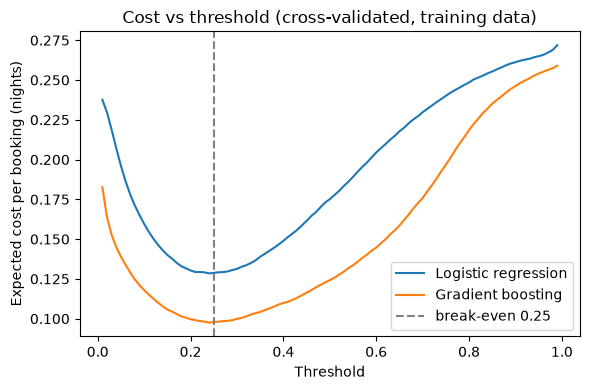

In [15]:
# Out-of-fold predictions and threshold choice (training data only)
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss,
                             log_loss, roc_curve, precision_recall_curve, confusion_matrix)
from sklearn.calibration import calibration_curve

# Final fitted pipelines from Section 4
models = {
    "Logistic regression": logreg_search.best_estimator_,
    "Gradient boosting": gb_search.best_estimator_,
}

# Cost assumptions from Section 1, in units of one night's revenue
C_FN = 1.0      # missed cancellation: the room stays empty
C_FP = 1 / 3    # false alarm: guest flagged who would have come
print("Break-even threshold:", round(C_FP / (C_FP + C_FN), 2))

def expected_cost(y_true, p, t):
    """Average cost per booking if we flag every booking with probability >= t."""
    flag = p >= t
    fn = np.sum(~flag & (y_true == 1))
    fp = np.sum(flag & (y_true == 0))
    return (C_FN * fn + C_FP * fp) / len(y_true)

y_tr = y_train.to_numpy()
thresholds = np.linspace(0.01, 0.99, 99)

oof_proba, best_t = {}, {}
fig, ax = plt.subplots(figsize=(6, 4))
for name, est in models.items():
    # Each training row is predicted by a model that did not see it
    oof_proba[name] = cross_val_predict(
        clone(est), X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
    )[:, 1]
    costs = [expected_cost(y_tr, oof_proba[name], t) for t in thresholds]
    best_t[name] = thresholds[int(np.argmin(costs))]
    ax.plot(thresholds, costs, label=name)
    print(f"{name}: best threshold {best_t[name]:.2f}, cost {min(costs):.3f} per booking")

ax.axvline(0.25, color="grey", linestyle="--", label="break-even 0.25")
ax.set_xlabel("Threshold")
ax.set_ylabel("Expected cost per booking (nights)")
ax.set_title("Cost vs threshold (cross-validated, training data)")
ax.legend()
plt.tight_layout()
plt.show()

In [16]:
# One-time test set check

# Test set is used here for the first time. Thresholds are fixed from Cell 1.
y_te = y_test.to_numpy()
proba_test = {name: est.predict_proba(X_test)[:, 1] for name, est in models.items()}

rows = []
for name, p in proba_test.items():
    rows.append({
        "model": name,
        "PR-AUC": average_precision_score(y_te, p),
        "ROC-AUC": roc_auc_score(y_te, p),
        "Brier": brier_score_loss(y_te, p),
        "Log loss": log_loss(y_te, p),
        "Cost @0.50": expected_cost(y_te, p, 0.50),
        "Cost @0.25": expected_cost(y_te, p, 0.25),
        "Cost @chosen": expected_cost(y_te, p, best_t[name]),
        "chosen t": best_t[name],
    })
results = pd.DataFrame(rows).set_index("model").round(3)
print(results)

# Reference points that need no model
print("\nCost if we flag nobody:  ", round(C_FN * y_te.mean(), 3))
print("Cost if we flag everybody:", round(C_FP * (1 - y_te.mean()), 3))

# Confusion matrices at the chosen thresholds (rows = actual, columns = predicted)
for name, p in proba_test.items():
    print(f"\n{name} at t = {best_t[name]:.2f}")
    print(confusion_matrix(y_te, p >= best_t[name]))

                     PR-AUC  ROC-AUC  Brier  Log loss  Cost @0.50  Cost @0.25  \
model                                                                           
Logistic regression   0.653    0.833  0.142     0.437       0.170       0.123   
Gradient boosting     0.775    0.898  0.113     0.351       0.121       0.094   

                     Cost @chosen  chosen t  
model                                        
Logistic regression         0.123      0.24  
Gradient boosting           0.094      0.24  

Cost if we flag nobody:   0.275
Cost if we flag everybody: 0.242

Logistic regression at t = 0.24
[[8772 3872]
 [ 858 3944]]

Gradient boosting at t = 0.24
[[9591 3053]
 [ 630 4172]]


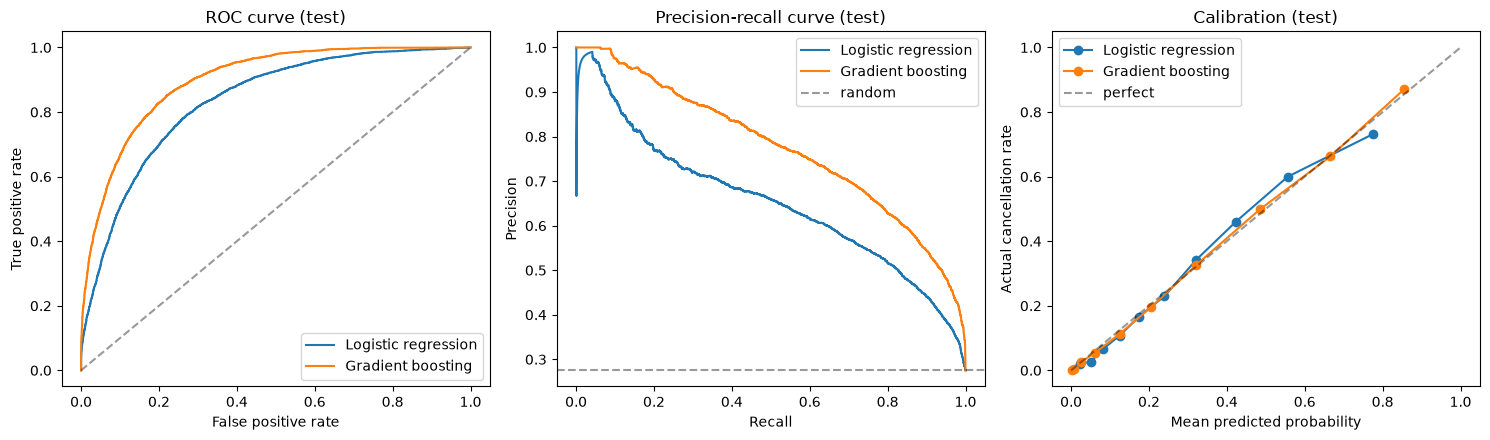

In [17]:
# ROC, PR and calibration curves

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for name, p in proba_test.items():
    # ROC curve
    fpr, tpr, _ = roc_curve(y_te, p)
    axes[0].plot(fpr, tpr, label=name)
    # Precision-recall curve
    prec, rec, _ = precision_recall_curve(y_te, p)
    axes[1].plot(rec, prec, label=name)
    # Calibration: predicted probability vs actual cancellation rate in each bin
    frac_pos, mean_pred = calibration_curve(y_te, p, n_bins=10, strategy="quantile")
    axes[2].plot(mean_pred, frac_pos, marker="o", label=name)

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
axes[0].set(title="ROC curve (test)", xlabel="False positive rate", ylabel="True positive rate")

axes[1].axhline(y_te.mean(), color="k", linestyle="--", alpha=0.4, label="random")
axes[1].set(title="Precision-recall curve (test)", xlabel="Recall", ylabel="Precision")

axes[2].plot([0, 1], [0, 1], "k--", alpha=0.4, label="perfect")
axes[2].set(title="Calibration (test)", xlabel="Mean predicted probability", ylabel="Actual cancellation rate")

for a in axes:
    a.legend()
plt.tight_layout()
plt.show()

In [18]:
# How much does the conclusion depend on the assumed 3:1 cost ratio?
# ratio = cost of a missed cancellation relative to a false alarm
rows = []
for ratio in [1.5, 2, 3, 5, 10]:
    c_fp = 1 / ratio                  # false alarm cost (a miss costs 1)
    t_star = c_fp / (1 + c_fp)        # break-even threshold for this ratio
    out = {"ratio": ratio, "threshold": round(t_star, 2)}
    for name, p in proba_test.items():
        flag = p >= t_star
        fn = np.sum(~flag & (y_te == 1))
        fp = np.sum(flag & (y_te == 0))
        out[name] = round((fn + c_fp * fp) / len(y_te), 3)
    out["flag nobody"] = round(y_te.mean(), 3)
    out["flag everybody"] = round(c_fp * (1 - y_te.mean()), 3)
    rows.append(out)
print(pd.DataFrame(rows).set_index("ratio"))

       threshold  Logistic regression  Gradient boosting  flag nobody  \
ratio                                                                   
1.5         0.40                0.179              0.136        0.275   
2.0         0.33                0.156              0.119        0.275   
3.0         0.25                0.123              0.094        0.275   
5.0         0.17                0.090              0.068        0.275   
10.0        0.09                0.055              0.042        0.275   

       flag everybody  
ratio                  
1.5             0.483  
2.0             0.362  
3.0             0.242  
5.0             0.145  
10.0            0.072  


**Conclusion:** Which model is better, by how much, and at which threshold would
you use it?

Gradient boosting is the better model. On the test set it reaches a PR-AUC of 0.775 against 0.653 for logistic regression, and a ROC-AUC of 0.898 against 0.833. At the cost-based threshold of 0.24 it costs 0.094 nights of revenue per booking, compared with 0.123 for logistic regression, which is 24% lower. The best strategy that needs no model is flagging every booking, at 0.242 per booking. Against that, gradient boosting cuts expected cost by about 61% and logistic regression by about 49%. Per 1,000 bookings, that is roughly 148 fewer lost nights than flagging everyone and 29 fewer than logistic regression.

We would use gradient boosting and flag bookings with a predicted cancellation probability of 0.24 or higher. This is close to the break-even threshold of 0.25 implied by our 3:1 cost ratio, which is what we expect when probabilities are well calibrated, and the gradient boosting calibration curve sits almost on the diagonal. The cost curve is flat between about 0.2 and 0.3, so the exact value is not critical. At 0.24 the model flags 41% of bookings, catches 87% of actual cancellations (4,172 of 4,802), and is correct 58% of the time when it flags one. The default 0.5 cutoff would raise the expected cost by 29% (0.121 versus 0.094).

This result rests on our assumed costs and on removing duplicate rows, which lowered the cancellation rate from 37% to 27.5%. The test set was used once, with the threshold fixed beforehand from training data only.

We also checked how sensitive this is to the assumed cost ratio by testing missed-cancellation to false-alarm cost ratios from 1.5:1 to 10:1, using the break-even threshold for each ratio. Gradient boosting had the lowest expected cost in every case, about 24% below logistic regression, and both models beat the best no-model strategy. The gain over that strategy was largest near our assumed 3:1 ratio (about 61%) and smallest at 10:1 (about 42%), where flagging every booking becomes cheap. The recommendation therefore does not depend on the exact cost ratio, but the hotel should use the threshold that matches its own costs.


## 6. Interpretation and recommendation (15%)

Explain what drives the predictions, check that the directions agree with your
EDA, and turn the results into a recommendation for the decision-maker from
Section 1.

                           feature  drop in PR-AUC      sd
11                         country          0.1683  0.0028
1                        lead_time          0.1348  0.0053
23       total_of_special_requests          0.1196  0.0017
12                  market_segment          0.1081  0.0029
19                           agent          0.1052  0.0026
15          previous_cancellations          0.0693  0.0032
21                   customer_type          0.0489  0.0014
18                    deposit_type          0.0402  0.0023
22                             adr          0.0329  0.0013
3         arrival_date_week_number          0.0200  0.0014
16  previous_bookings_not_canceled          0.0181  0.0009
6             stays_in_week_nights          0.0103  0.0010


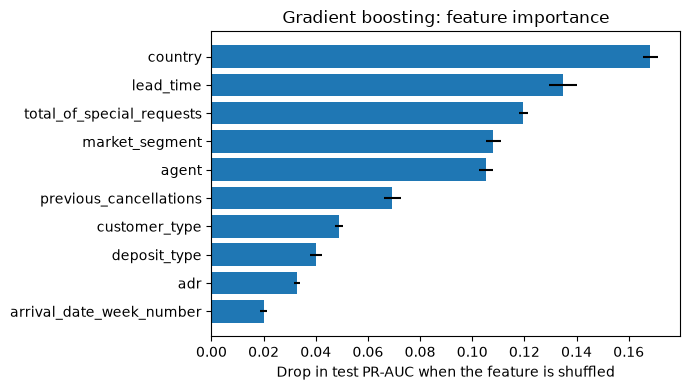

In [19]:
# What drives gradient boosting (permutation importance)

from sklearn.inspection import permutation_importance
from sklearn.model_selection import cross_val_score

# Shuffle one original column at a time and see how much test PR-AUC drops.
# A big drop means the model relies on that feature. This is interpretation only,
# no modelling choice depends on it.
gb_best = models["Gradient boosting"]
perm = permutation_importance(
    gb_best, X_test, y_test, scoring="average_precision",
    n_repeats=5, random_state=SEED, n_jobs=-1,
)
imp = pd.DataFrame({
    "feature": X_test.columns,
    "drop in PR-AUC": perm.importances_mean,
    "sd": perm.importances_std,
}).sort_values("drop in PR-AUC", ascending=False)
print(imp.head(12).round(4))

# Bar chart of the top 10 (reversed so the biggest is on top)
top = imp.head(10).iloc[::-1]
plt.figure(figsize=(7, 4))
plt.barh(top["feature"], top["drop in PR-AUC"], xerr=top["sd"])
plt.xlabel("Drop in test PR-AUC when the feature is shuffled")
plt.title("Gradient boosting: feature importance")
plt.tight_layout()
plt.show()

In [20]:
# What drives logistic regression (coefficients)

# Numeric features were standardised, so coefficient sizes are roughly comparable.
# Positive = raises the odds of cancellation, negative = lowers them.
lr_best = models["Logistic regression"]
names = lr_best.named_steps["prep"].get_feature_names_out()
coefs = pd.Series(lr_best.named_steps["model"].coef_[0], index=names).sort_values()

print("Pushes toward cancellation:")
print(coefs.tail(8)[::-1].round(2))
print("\nPushes toward staying:")
print(coefs.head(8).round(2))

Pushes toward cancellation:
cat__arrival_date_month_December     5.81
cat__arrival_date_month_November     4.79
cat__arrival_date_month_October      3.72
cat__arrival_date_month_September    2.49
cat__deposit_type_Non Refund         1.81
cat__country_PRT                     1.53
cat__arrival_date_month_August       1.30
cat__agent_240                       1.27
dtype: float64

Pushes toward staying:
cat__arrival_date_month_January    -5.75
cat__arrival_date_month_February   -4.56
cat__arrival_date_month_March      -3.68
num__arrival_date_week_number      -3.24
cat__arrival_date_month_April      -2.48
cat__deposit_type_No Deposit       -1.58
cat__arrival_date_month_May        -1.53
cat__agent_28                      -1.19
dtype: float64


In [21]:
# Do the directions agree with the raw data?

# Cancellation rates in the cleaned (deduplicated) data, to compare with what the models learned
for col in ["deposit_type", "market_segment", "customer_type", "hotel"]:
    print(data.groupby(col)["is_canceled"].agg(["mean", "count"]).round(3), "\n")

# Lead time in buckets
bins = pd.cut(data["lead_time"], [-1, 7, 30, 90, 180, 365, 800])
print(data.groupby(bins, observed=True)["is_canceled"].agg(["mean", "count"]).round(3), "\n")

# Guests who cancelled before versus guests who did not
print(data.groupby(data["previous_cancellations"] > 0)["is_canceled"].agg(["mean", "count"]).round(3))

               mean  count
deposit_type              
No Deposit    0.267  86084
Non Refund    0.947   1038
Refundable    0.243    107 

                 mean  count
market_segment              
Aviation        0.199    226
Complementary   0.123    692
Corporate       0.121   4200
Direct          0.147  11780
Groups          0.271   4921
Offline TA/TO   0.148  13855
Online TA       0.354  51553
Undefined       1.000      2 

                  mean  count
customer_type                
Contract         0.163   3135
Group            0.098    541
Transient        0.301  71862
Transient-Party  0.153  11691 

               mean  count
hotel                     
City Hotel    0.301  53274
Resort Hotel  0.235  33955 

             mean  count
lead_time               
(-1, 7]     0.084  18203
(7, 30]     0.254  16326
(30, 90]    0.320  22720
(90, 180]   0.350  18224
(180, 365]  0.397  11192
(365, 800]  0.408    564 

                         mean  count
previous_cancellations              
Fal

In [22]:
# How much does the model lean on the risky features?

# Cross-validated PR-AUC on the TRAINING set with groups of features removed.
# The final model is not changed, this is a sensitivity check.
def make_prep(X):
    nums = X.select_dtypes(include="number").columns.tolist()
    cats = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer(
        [("num", numeric_pipe, nums), ("cat", categorical_pipe, cats)],
        sparse_threshold=0,
    )

gb_model = gb_best.named_steps["model"]   # same tuned settings
scenarios = {
    "All features": [],
    "Without borderline (waiting list, adr, special requests)":
        ["days_in_waiting_list", "adr", "total_of_special_requests"],
    "Without deposit_type": ["deposit_type"],
}

rows = []
for label, drop in scenarios.items():
    Xs = X_train.drop(columns=drop)
    pipe = Pipeline([("prep", make_prep(Xs)), ("model", clone(gb_model))])
    s = cross_val_score(pipe, Xs, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    rows.append({"setup": label, "PR-AUC mean": s.mean(), "PR-AUC sd": s.std()})
print(pd.DataFrame(rows).round(3))

                                               setup  PR-AUC mean  PR-AUC sd
0                                       All features        0.766      0.004
1  Without borderline (waiting list, adr, special...        0.702      0.007
2                               Without deposit_type        0.764      0.005


In [23]:
# Risk bands for the recommendation

# How does the real cancellation rate change across predicted-risk bands (test set)?
p = proba_test["Gradient boosting"]
bands = pd.cut(p, [0, 0.10, 0.24, 0.50, 1.0], include_lowest=True)
band_table = (pd.DataFrame({"band": bands, "cancelled": y_te})
              .groupby("band", observed=True)["cancelled"]
              .agg(count="count", actual_rate="mean").round(3))
print(band_table)

               count  actual_rate
band                             
(-0.001, 0.1]   7263        0.023
(0.1, 0.24]     2958        0.156
(0.24, 0.5]     2999        0.364
(0.5, 1.0]      4226        0.729


In [24]:
# Optional cell checks which borderline feature matters and gives the raw rates for country and month. 
# It touches only training data, so the test set stays used once.

# 1) Which borderline feature matters? Drop each one separately (CV PR-AUC, training data)
for col in ["total_of_special_requests", "adr", "days_in_waiting_list"]:
    Xs = X_train.drop(columns=[col])
    pipe = Pipeline([("prep", make_prep(Xs)), ("model", clone(gb_model))])
    s = cross_val_score(pipe, Xs, y_train, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"Without {col}: {s.mean():.3f} +/- {s.std():.3f}")

# 2) Expected cost without all three borderline features (out-of-fold, training data, threshold 0.25)
drop3 = ["days_in_waiting_list", "adr", "total_of_special_requests"]
Xs = X_train.drop(columns=drop3)
pipe = Pipeline([("prep", make_prep(Xs)), ("model", clone(gb_model))])
p_oof = cross_val_predict(pipe, Xs, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
print("Cost without borderline features:", round(expected_cost(y_tr, p_oof, 0.25), 3))
print("Cost with all features:          ", round(expected_cost(y_tr, oof_proba["Gradient boosting"], 0.25), 3))
print("Cost if we flag everybody:       ", round(C_FP * (1 - y_tr.mean()), 3))

# 3) Raw cancellation rate by arrival month, and Portugal versus other countries
month_order = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
print(data.groupby("arrival_date_month")["is_canceled"].mean().reindex(month_order).round(3))
print(data.groupby(data["country"] == "PRT")["is_canceled"].agg(["mean", "count"]).round(3))



Without total_of_special_requests: 0.708 +/- 0.008
Without adr: 0.759 +/- 0.004
Without days_in_waiting_list: 0.767 +/- 0.005
Cost without borderline features: 0.109
Cost with all features:           0.098
Cost if we flag everybody:        0.242
arrival_date_month
January      0.221
February     0.232
March        0.244
April        0.305
May          0.293
June         0.303
July         0.318
August       0.322
September    0.246
October      0.237
November     0.212
December     0.269
Name: is_canceled, dtype: float64
          mean  count
country              
False    0.238  59874
True     0.358  27355


**What drives the predictions.** Gradient boosting relies most on country (test PR-AUC drops by 0.168 when it is shuffled), lead time (0.135), total special requests (0.120), market segment (0.108) and booking agent (0.105). Previous cancellations (0.069), customer type (0.049) and deposit type (0.040) follow. Logistic regression agrees where its coefficients can be read. Non Refund deposits (+1.81) and Portuguese guests (+1.53) raise the odds of cancellation, while No Deposit lowers them (-1.58). Its month coefficients are very large and offset each other (December +5.81, January -5.75, week number -3.24) because month and week number encode almost the same information, so we do not interpret them individually. The raw data confirms this. Cancellation rates peak in summer (30 to 32% from April to August) and are lowest in November and January (21 to 22%), and December sits at 26.9%, far from what its +5.81 coefficient would suggest. Portuguese guests cancel 35.8% of the time versus 23.8% for other guests, which matches the positive country coefficient.

- **Interpretation:** The directions agree with the EDA. Cancellation rises steadily with lead time, from 8.4% for bookings made 7 days ahead or less to about 40% beyond 180 days. Guests with a previous cancellation cancel 68% of the time versus 27% for others. Online travel agent bookings cancel 35%, against 12% for corporate and 15% for direct bookings. Our Section 1 hypothesis is partly supported. Lead time, market segment and previous cancellations are among the top six drivers, but deposit type ranks only eighth, while country, special requests and agent matter more than we expected. Removing deposit type changes cross-validated PR-AUC only from 0.766 to 0.764, so the model does not depend on the unusual Non Refund pattern. Removing the three borderline features (special requests, adr, waiting list) lowers it from 0.766 to 0.702, but almost all of that comes from special requests alone (0.708 without it). Removing adr gives 0.759 and removing waiting list gives 0.767, which is no change. Without all three features, the expected cost rises from 0.098 to 0.109 per booking, still well below the 0.242 of flagging every booking. The model without them also still beats logistic regression with all features (0.635).

- **Recommendation:** The hotel should use gradient boosting and flag bookings with a predicted cancellation probability of 0.24 or higher, which is about 41% of bookings. On the test set the predicted risk separates bookings well. Bookings below 0.10 (42% of all bookings) cancelled only 2.3% of the time and can be treated as firm. Bookings between 0.10 and 0.24 (17%) cancelled 15.6% of the time and are not worth intervening on under our costs. Those between 0.24 and 0.50 (17%) cancelled 36.4% of the time and suit a light intervention such as a reminder. Those above 0.50 (24%) cancelled 72.9% of the time and are the first candidates for a deposit or reconfirmation request. Because the probabilities are well calibrated, summing them across the bookings for one arrival date gives an expected number of cancellations that the hotel can use as a starting point for its overbooking level. We have not tested this. Before rolling anything out, the hotel should pilot the policy on part of its bookings to see whether deposit requests actually reduce cancellations or only lose bookings, and it should rerun the threshold with its own cost figures. The hotel should also check whether its booking system records special requests at the time of booking. If it does not, the version of the model without that feature (cost 0.109 per booking) is the safer one to deploy. Since country is the strongest driver, the hotel should decide whether it is comfortable applying stricter terms by guest nationality, or whether to drop that feature and accept a lower score.

- **Limitations:**
  - The 3:1 cost ratio is an assumption. The sensitivity check in Section 5 shows the model ranking holds from 1.5:1 to 10:1, but the best threshold changes.
  - We removed 31,994 duplicate rows because the data has no booking ID. Some may be real separate bookings, and removing them lowered the cancellation rate from 37% to 27.5%.
  - The split is random, but a hotel predicts future bookings from past ones, so performance on truly future data is probably lower. The data covers only two Portuguese hotels from 2015 to 2017.
  - Special requests may be partly added after booking, and it is the one borderline feature the model clearly needs. Without it, PR-AUC drops from 0.766 to 0.708. The adr feature has a small effect (0.759) and waiting list none (0.767). If a hotel's system does not record special requests at booking time, it should expect results closer to the lower figure. Even then, the cost per booking is 0.109 against 0.242 for flagging everyone.
  - Non Refund bookings cancelled 95% of the time, which we cannot explain commercially. The model does not depend on it, but it suggests a recording quirk in the data.
  - Permutation importance shows what the model relies on, not what causes cancellation. Country and agent are tied to these hotels' own markets and partners and may not transfer elsewhere.
  - The model ranks risk and does not show that a deposit or reconfirmation request would prevent a cancellation.

## 7. Reproducibility (5%)

Before the upload (before Block 7, 17:10):

- [ ] *Kernel → Restart & Run All* runs without errors, ideally on a teammate's computer
- [ ] every number you report is computed in this notebook
- [ ] the data file is included or downloaded by the code; paths are relative
- [ ] seeds are fixed, and a re-run gives identical results